# M67 Analysis

In [6]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [10]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)
        

Text(0.5, 1.0, 'M67 G-band image')

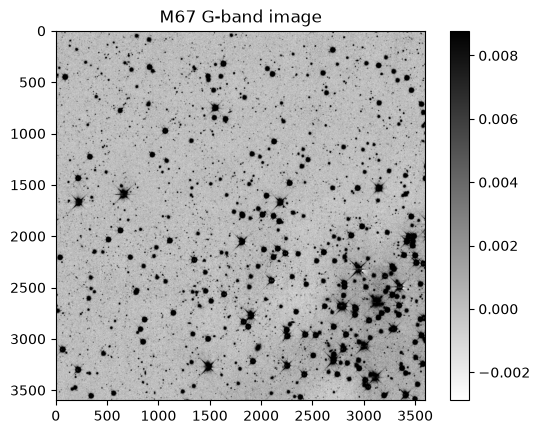

In [9]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M67 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M67 G-band image")

Text(0.5, 1.0, 'M67 R-band image')

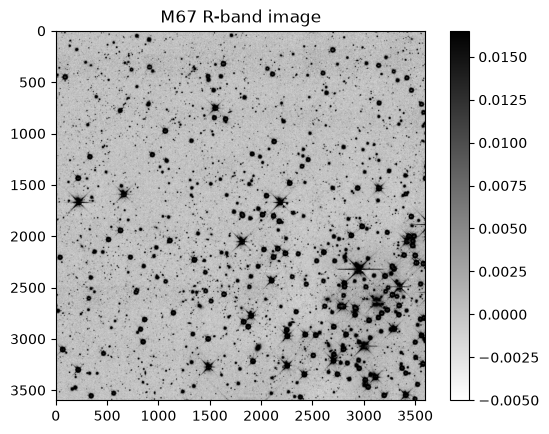

In [10]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M67 R-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M67 R-band image")

In [12]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [16]:
# Calculate FWHM for M67 G-band

M67Gstars = [(1652.23, 2890.77),(1332.9, 2945.23),(3234.83, 1962), (3413.16, 453.704),(1800.83, 3299.43)]

M67G_fwhm = calc_fwhm('M67 G-band image.fits', M67Gstars)

print("G-band FWHM:", M67G_fwhm)
print("Mean G-band FWHM:", np.mean(M67G_fwhm))
print("Median G-band FWHM:", np.median(M67G_fwhm))

The FWHM of the stars in M67 G-band image.fits in pixels are [4.75709268 5.77459119 5.27015913 4.94039666 4.77424869]
G-band FWHM: [4.75709268 5.77459119 5.27015913 4.94039666 4.77424869]
Mean G-band FWHM: 5.103297669904445
Median G-band FWHM: 4.9403966604812055


In [15]:
# Calculate FWHM for M67 R-band

M67Rstars = [(2172.5, 1942.17),(2989.81, 1162.01),(3391.04, 1711.84),(1236.31, 3301.88),(1994.18, 1236.31)]
M67R_fwhm = calc_fwhm('M67 R-band image.fits', M67Rstars)

print("R-band FWHM:", M67R_fwhm)
print("Mean R-band FWHM:", np.mean(M67R_fwhm))
print("Median R-band FWHM:", np.median(M67R_fwhm))

The FWHM of the stars in M67 R-band image.fits in pixels are [4.9067584  4.4778736  4.14880319 4.34893221 5.0652364 ]
R-band FWHM: [4.9067584  4.4778736  4.14880319 4.34893221 5.0652364 ]
Mean R-band FWHM: 4.589520761495637
Median R-band FWHM: 4.47787360333826


**Measure Photometry of Stars**

In [7]:
#read in the G-band image
M67data_G, M67header_G = fits.getdata('M67 G-band image.fits',header=True)

In [8]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M67mean_G, M67median_G, M67std_G = sigma_clipped_stats(M67data_G, sigma=3.0)

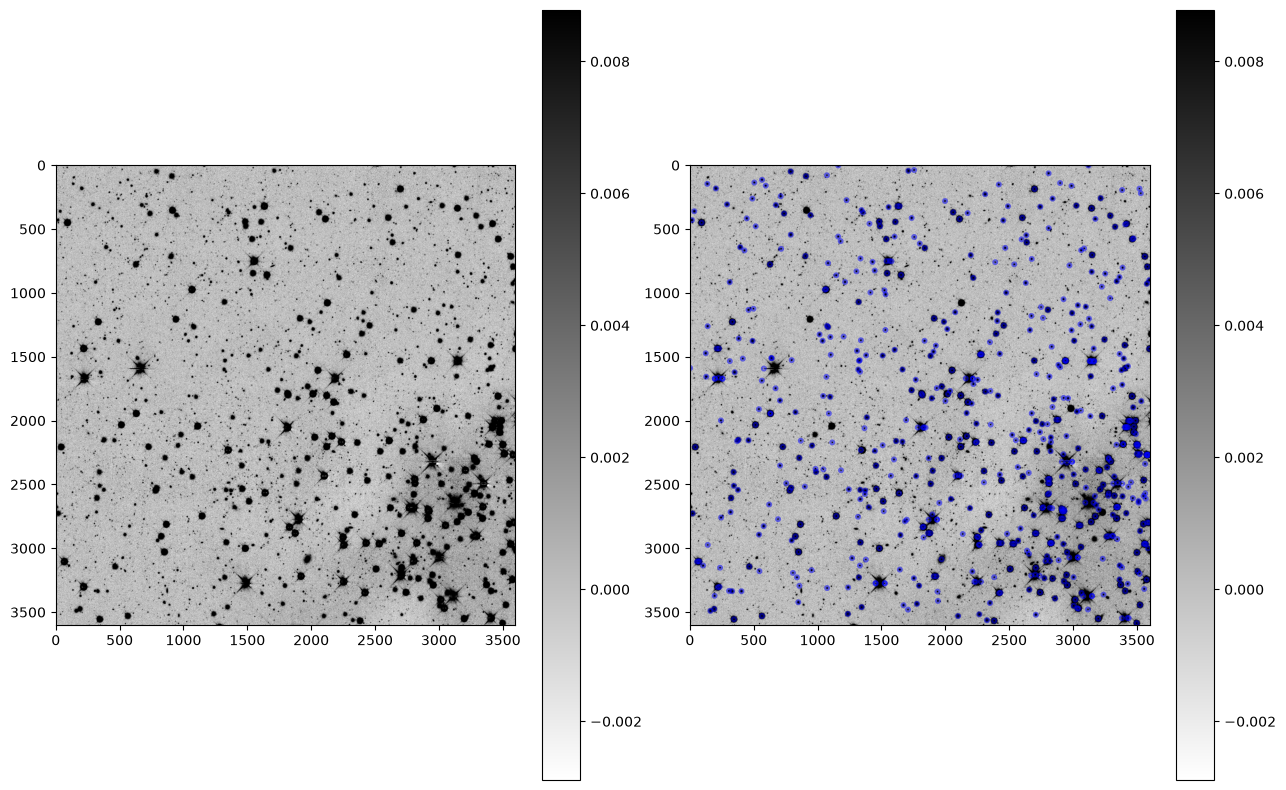

In [11]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=5.10, threshold=80.*M67std_G)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M67sources_G = daofind(M67data_G - M67median_G)

# convert pixel locations of images to ra and dec using the image header
wcs_G = WCS(M67header_G)
M67ra_G,M67dec_G = wcs_G.wcs_pix2world(M67sources_G['xcentroid'],M67sources_G['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M67data_G)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M67sources_G['xcentroid'], M67sources_G['ycentroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M67data_G)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

Text(0.5, 1.0, 'M67 G-band')

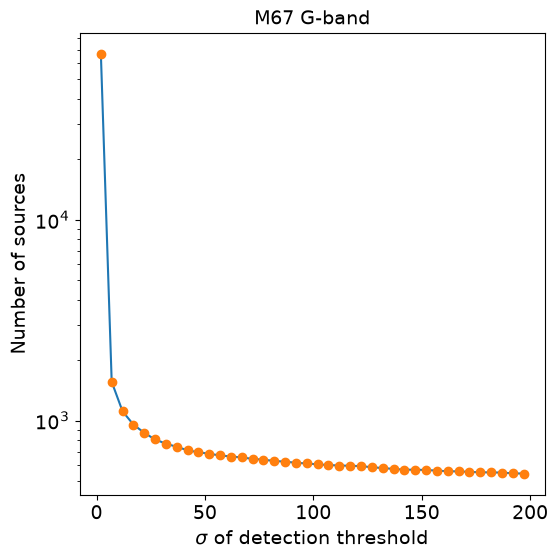

In [13]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_G = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=5.10, threshold=thresh*M67std_G)
    M67sources_Gtmp = daofind(M67data_G - M67median_G)
    nsources_G[ithresh] = len(M67sources_Gtmp)

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_G)
ax.plot(thresharr,nsources_G, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M67 G-band', fontsize=14)